# CAMUS denoising with DRUNet: pretrained vs fine-tuned

In this notebook we denoise echocardiographic images with a deep network, using the [DeepInverse](https://deepinv.org) library, and we compare three versions of each test image against the same clean reference:

1. **Perturbed** — the degraded image, with no restoration (the baseline).
2. **Median filter** - classical approach without training. 
3. **DRUNet pretrained** — a denoiser trained by someone else, used as it is.
4. **DRUNet fine-tuned** — the same denoiser after a short additional training on CAMUS pairs.

Here *clean* means the original CAMUS image, before the synthetic perturbations; it is not a speckle-free ideal image. We measure image similarity with PSNR and SSIM, not the effect on any downstream task.

## Kaggle setup

1. Create a Kaggle Notebook and select a GPU under **Settings → Accelerator** (one GPU is enough).
2. Upload the CAMUS folder as a private Kaggle Dataset and attach it with **Add Input**. It must contain `index.csv` and the `train/`, `val/`, `test/` folders, each with `clean/` and `perturbed/` subfolders.
3. Turn **Internet** on, needed once to install the packages and download the pretrained weights.

## 1. Background

**Denoising as supervised regression.** We observe a degraded image $y$ and want to estimate the original image $x$. A denoiser is a function $D(y) \approx x$. Classical filters build $D$ from a hand-made assumption, for instance that neighbouring pixels have similar values. A deep denoiser learns $D_\theta$, a neural network with weights $\theta$, from examples: given $N$ pairs $(y_i, x_i)$, training looks for

$$\theta^\star = \arg\min_\theta \; \frac{1}{N}\sum_{i=1}^{N} \big\| D_\theta(y_i) - x_i \big\|^2 ,$$

the weights that minimise the mean squared error (MSE) between output and target. This needs pairs. In CAMUS we have them because the perturbation was applied synthetically to a known image; the same holds if you add synthetic noise to your in-house images.

**DRUNet.** A U-Net with residual blocks, designed for denoising. Besides the image, it receives a noise level $\sigma$ (in intensity units, with images in $[0,1]$), so one network can denoise more or less strongly. At inference time $\sigma$ is its only knob.

The DeepInverse weights were **trained on natural images with additive Gaussian noise**. We have two mismatches: the *image domain* (ultrasound instead of natural images) and the *degradation* (blur, contrast changes, speckle and impulsive noise are not Gaussian noise). Using the network as it is costs nothing, but we should not assume it works well.

**Fine-tuning.** We start from the pretrained weights and keep training on in-domain pairs with a small learning rate. It is cheaper than training from scratch, because the network already knows how to denoise; it only needs to adapt. It is not guaranteed to help.

**Roles of the three splits.**

| Split | Used for |
|---|---|
| train | updating the weights (gradient steps) |
| validation | decisions: the value of $\sigma$, and when to stop training |
| test | the final numbers, evaluated once at the end |

*Early stopping* means we check the validation loss after every epoch, keep the weights with the lowest value, and stop if it has not improved for a few consecutive epochs. If no epoch beats the pretrained network, we keep the pretrained one.

**Metrics.** Both compare a restored image $\hat{x}$ with the clean image $x$, with intensities in $[0,1]$.

* **PSNR** (dB): $10\log_{10}(1/\mathrm{MSE})$. Higher is better. It is a pixel-wise measure, blind to structure.
* **SSIM** (from $-1$ to $1$, where 1 means identical): compares local mean, contrast and structure in small windows, closer to how images are perceived.

Both measure similarity to the clean image, not diagnostic usefulness.

In [ ]:
%pip install -q deepinv pydicom

In [1]:
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import pydicom
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from scipy.ndimage import binary_closing, binary_erosion, median_filter
import deepinv as dinv

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)   # it should say cuda; otherwise enable the GPU in the Kaggle settings

# Configuration (None means: use all the images of the split)
N_TRAIN, N_VAL, N_TEST = 400, 100, None
PATCH_SIZE, BATCH_SIZE = 128, 16   # training uses random crops, evaluation uses full images
LEARNING_RATE = 5e-5
MAX_EPOCHS, PATIENCE, MIN_DELTA = 20, 3, 1e-6

Device: cuda


## 2. Data

`index.csv` lists the correspondence between perturbed and clean files and the split of each image. Each row is one image, and the file names differ between folders (the perturbed ones have a `_d0` suffix). Images are read from DICOM and rescaled to $[0,1]$, the range expected by the network and the metrics. We keep everything in memory as pairs `(perturbed, clean)`; the number of images per split is set in the configuration above to keep the run short on the free GPU.

train:   0%|          | 0/400 [00:00<?, ?it/s]

val:   0%|          | 0/100 [00:00<?, ?it/s]

test:   0%|          | 0/200 [00:00<?, ?it/s]

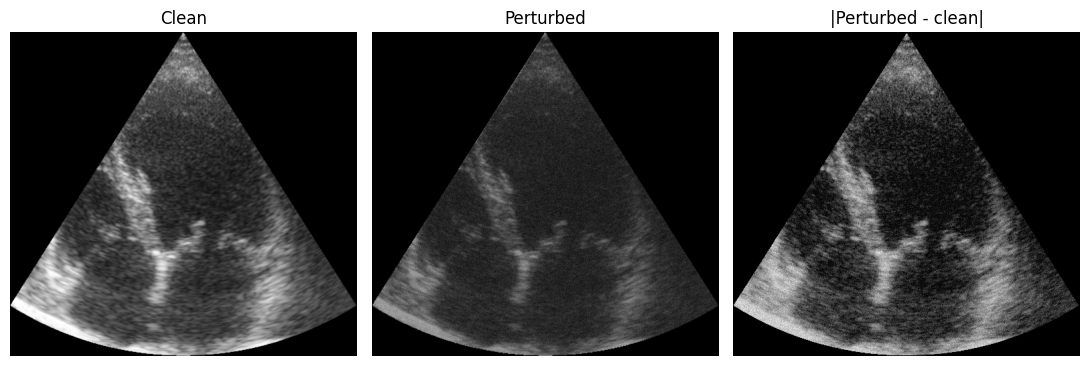

In [2]:
ROOT = next(Path("/kaggle/input").rglob("index.csv")).parent
index = pd.read_csv(ROOT / "index.csv")

def read_image(path):
    ds = pydicom.dcmread(path)
    img = ds.pixel_array.astype(np.float32)
    if img.ndim == 3:   # RGB: average the channels; multi-frame: keep the first frame
        img = img.mean(-1) if ds.SamplesPerPixel == 3 else img[0]
    return img / (2 ** int(ds.BitsStored) - 1)

def load_pairs(split, n=None):
    rows = index[index["split"] == split]
    if n is not None:
        rows = rows.sample(min(n, len(rows)), random_state=SEED)
    pairs = []
    for r in tqdm(list(rows.itertuples()), desc=split):
        noisy = read_image(ROOT / split / "perturbed" / f"{r.perturbed_id}.dcm")   # adapt the extension if needed
        clean = read_image(ROOT / split / "clean" / f"{r.clean_id}.dcm")
        pairs.append((noisy, clean))
    return pairs

train_pairs = load_pairs("train", N_TRAIN)
val_pairs = load_pairs("val", N_VAL)
test_pairs = load_pairs("test", N_TEST)

noisy, clean = train_pairs[0]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, img, title in zip(axes, [clean, noisy, np.abs(noisy - clean)], ["Clean", "Perturbed", "|Perturbed - clean|"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1 if title != "|Perturbed - clean|" else None)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Pretrained DRUNet and choice of $\sigma$

We load the grayscale DRUNet weights from DeepInverse. `denoise` runs the network on a full image: DRUNet downsamples the image several times, so we pad it to a multiple of 16 and crop the result back.

Before using the model we need a value of $\sigma$. We do not know the composition of the perturbation, so we choose it on the **validation** set: we try a few values and keep the one with the lowest validation MSE. The same $\sigma$ is used for the pretrained and the fine-tuned network, so that the comparison isolates the effect of the weights.

In [3]:
# Use the same sector mask derived from the clean reference for every method.
def ultrasound_mask(clean, closing_size=5):
    mask = np.asarray(clean) > 0
    mask = binary_closing(mask, structure=np.ones((closing_size, closing_size), dtype=bool))
    if not mask.any():
        raise ValueError("Empty ultrasound-sector mask; inspect this image.")
    return mask


def masked_mse(clean, img, mask=None):
    if mask is None:
        mask = ultrasound_mask(clean)
    return float(np.mean((clean[mask] - img[mask]) ** 2))


def masked_metrics(clean, img, mask=None):
    if mask is None:
        mask = ultrasound_mask(clean)
    mse = masked_mse(clean, img, mask)
    psnr = float(-10 * np.log10(mse)) if mse > 0 else float("inf")

    # SSIM uses local 7x7 windows. Keep windows fully inside the sector.
    _, ssim_map = structural_similarity(clean, img, data_range=1.0, full=True, win_size=7)
    valid_mask = binary_erosion(mask, iterations=3)
    if not valid_mask.any():
        raise ValueError("No valid sector pixels remain after SSIM-window erosion.")
    ssim = float(ssim_map[valid_mask].mean())
    return psnr, ssim


In [4]:
pretrained = dinv.models.DRUNet(in_channels=1, out_channels=1, pretrained="download", device=DEVICE).eval()

@torch.no_grad()
def denoise(model, noisy, sigma):
    x = torch.from_numpy(noisy)[None, None].to(DEVICE)
    h, w = x.shape[-2:]
    x = F.pad(x, (0, -w % 16, 0, -h % 16), mode="replicate")
    return model(x, sigma)[0, 0, :h, :w].clamp(0, 1).cpu().numpy()

def val_mse(model, sigma):
    return float(np.mean([masked_mse(clean, denoise(model, noisy, sigma)) for noisy, clean in val_pairs]))

val_by_sigma = {s: val_mse(pretrained, s / 255) for s in (2, 5, 10, 15, 20, 30, 50)}
for s, v in val_by_sigma.items():
    print(f"sigma = {s:2d}/255   validation MSE = {v:.5f}")

SIGMA = min(val_by_sigma, key=val_by_sigma.get) / 255
print(f"\nSelected sigma = {SIGMA * 255:.0f}/255")

Downloading: "https://huggingface.co/deepinv/drunet/resolve/main/drunet_deepinv_gray_finetune_26k.pth?download=true" to /root/.cache/torch/hub/checkpoints/drunet_deepinv_gray_finetune_26k.pth


100%|██████████| 125M/125M [00:01<00:00, 98.5MB/s] 


sigma =  2/255   validation MSE = 0.01151
sigma =  5/255   validation MSE = 0.01121
sigma = 10/255   validation MSE = 0.01044
sigma = 15/255   validation MSE = 0.00965
sigma = 20/255   validation MSE = 0.00899
sigma = 30/255   validation MSE = 0.00805
sigma = 50/255   validation MSE = 0.00736

Selected sigma = 50/255


The validation MSE decreases as $\sigma$ increases within the tested range. The lowest MSE (0.00736) is obtained with $\sigma = 50/255$, which is therefore selected for the following experiments.

Since this is the largest tested value, we cannot conclude that it is globally optimal. However, it is the best choice among the evaluated candidates according to the validation MSE.

The same $\sigma$ will be used for both the pretrained and fine-tuned models, allowing us to compare the effect of adapting the network weights to CAMUS.

## 4. Fine-tuning with early stopping

We copy the pretrained network and train all its weights on random **paired crops**: the same region is cut from the perturbed and the clean image, and the network is trained to map the first onto the second with the MSE loss. Crops make each step cheap; validation uses full images.

The loop follows the classical pipeline:

1. the validation MSE of the pretrained network is the starting point (epoch 0);
2. in each epoch we update the weights on the training set, then measure the validation MSE;
3. if it improves by more than `MIN_DELTA` we store the weights as the best so far, otherwise we count one more epoch without improvement;
4. after `PATIENCE` epochs without improvement we stop, and we restore the best weights.

The test set is not used here.

Epoch  0 | val MSE 0.00736  (pretrained)
Epoch  1 | train MSE 0.00414 | val MSE 0.00608 | best so far
Epoch  2 | train MSE 0.00457 | val MSE 0.00553 | best so far
Epoch  3 | train MSE 0.00306 | val MSE 0.00551 | best so far
Epoch  4 | train MSE 0.00341 | val MSE 0.00588 | no improvement (1/3)
Epoch  5 | train MSE 0.00378 | val MSE 0.00629 | no improvement (2/3)
Epoch  6 | train MSE 0.00307 | val MSE 0.00385 | best so far
Epoch  7 | train MSE 0.00304 | val MSE 0.00491 | no improvement (1/3)
Epoch  8 | train MSE 0.00314 | val MSE 0.00427 | no improvement (2/3)
Epoch  9 | train MSE 0.00292 | val MSE 0.00360 | best so far
Epoch 10 | train MSE 0.00297 | val MSE 0.00408 | no improvement (1/3)
Epoch 11 | train MSE 0.00267 | val MSE 0.00346 | best so far
Epoch 12 | train MSE 0.00257 | val MSE 0.00373 | no improvement (1/3)
Epoch 13 | train MSE 0.00292 | val MSE 0.00374 | no improvement (2/3)
Epoch 14 | train MSE 0.00240 | val MSE 0.00395 | no improvement (3/3)
Early stopping

Best epoch: 11 | 

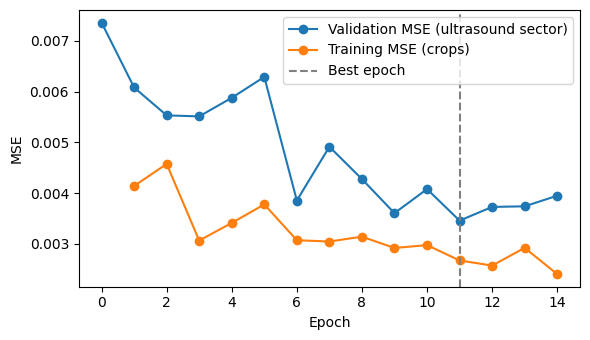

In [5]:
def random_crops(pairs, ids, size=PATCH_SIZE):
    noisy_crops, clean_crops = [], []
    for i in ids:
        noisy, clean = pairs[i]
        r = np.random.randint(0, noisy.shape[0] - size + 1)
        c = np.random.randint(0, noisy.shape[1] - size + 1)
        noisy_crops.append(noisy[r:r + size, c:c + size])
        clean_crops.append(clean[r:r + size, c:c + size])
    to_tensor = lambda crops: torch.from_numpy(np.stack(crops))[:, None].to(DEVICE)
    return to_tensor(noisy_crops), to_tensor(clean_crops)

finetuned = copy.deepcopy(pretrained)
optimizer = torch.optim.Adam(finetuned.parameters(), lr=LEARNING_RATE)

best_val = val_mse(pretrained, SIGMA)
best_state, best_epoch, bad_epochs = copy.deepcopy(finetuned.state_dict()), 0, 0
history = [dict(epoch=0, train=np.nan, val=best_val)]
print(f"Epoch  0 | val MSE {best_val:.5f}  (pretrained)")

for epoch in range(1, MAX_EPOCHS + 1):
    finetuned.train()
    order = np.random.permutation(len(train_pairs))
    losses = []
    for i in range(0, len(order), BATCH_SIZE):
        noisy, clean = random_crops(train_pairs, order[i:i + BATCH_SIZE])
        loss = F.mse_loss(finetuned(noisy, SIGMA), clean)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        losses.append(loss.item())

    finetuned.eval()
    val = val_mse(finetuned, SIGMA)
    history.append(dict(epoch=epoch, train=np.mean(losses), val=val))

    if val < best_val - MIN_DELTA:
        best_val, best_state, best_epoch, bad_epochs = val, copy.deepcopy(finetuned.state_dict()), epoch, 0
        status = "best so far"
    else:
        bad_epochs += 1
        status = f"no improvement ({bad_epochs}/{PATIENCE})"
    print(f"Epoch {epoch:2d} | train MSE {np.mean(losses):.5f} | val MSE {val:.5f} | {status}")

    if bad_epochs == PATIENCE:
        print("Early stopping")
        break

finetuned.load_state_dict(best_state)
finetuned.eval()
torch.save(best_state, "drunet_camus_finetuned.pt")   # saved in /kaggle/working
print(f"\nBest epoch: {best_epoch} | validation MSE: {best_val:.5f}")

history = pd.DataFrame(history)
plt.figure(figsize=(6, 3.5))
plt.plot(history.epoch, history.val, "o-", label="Validation MSE (ultrasound sector)")
plt.plot(history.epoch, history.train, "o-", label="Training MSE (crops)")
plt.axvline(best_epoch, color="gray", linestyle="--", label="Best epoch")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.tight_layout(); plt.show()

The validation point at epoch 0 is the pretrained model (baseline), before any fine-tuning.


During training, the validation MSE decreases from 0.00736 to 0.00346, reaching its minimum at epoch 11.

Although training continues until epoch 14, no further improvement is observed for three consecutive epochs. Early stopping is therefore triggered, and the weights from epoch 11 are restored.

Notice that the training and validation losses are not directly comparable: training uses random image crops and computes MSE over all pixels, whereas validation evaluates the full images and computes MSE only within the ultrasound sector.

## 5. Test set comparison

We evaluate the different versions against the clean reference on the test set, with the same $\sigma$ and the same metrics. The test set is used only here, once: nothing above was chosen with these images.

Training and validation MSE are not directly comparable, since the first is computed on crops and the second on full images.

In [6]:
def classical_denoise(img):
    """
    Apply a 5x5 median filter to a grayscale image.
    Input and output are 2D arrays in [0, 1].
    """
    return median_filter(img, size=5)

In [7]:
rows = []
for k, (noisy, clean) in enumerate(tqdm(test_pairs, desc="test")):
    versions = {"Perturbed": noisy,
                 "Median filter": classical_denoise(noisy),
                 "DRUNet pretrained": denoise(pretrained, noisy, SIGMA),
                 "DRUNet fine-tuned": denoise(finetuned, noisy, SIGMA)
}
    mask = ultrasound_mask(clean)  # compute only once per reference image
    for name, img in versions.items():
        psnr_sector, ssim_sector = masked_metrics(clean, img, mask)
        rows.append(dict(approach=name,
                         psnr=peak_signal_noise_ratio(clean, img, data_range=1.0),
                         ssim=structural_similarity(clean, img, data_range=1.0),
                         psnr_sector=psnr_sector,
                         ssim_sector=ssim_sector))
    if k == 0:
        example_clean, example_versions = clean, versions

results = pd.DataFrame(rows)
results.groupby("approach", sort=False)[["psnr", "ssim", "psnr_sector", "ssim_sector"]].agg(["mean", "std"]).round(3)

test:   0%|          | 0/200 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


psnr          ssim        psnr_sector        ssim_sector  \
                     mean    std   mean    std        mean    std        mean   
approach                                                                        
Perturbed             inf    NaN  0.795  0.157         inf    NaN       0.623   
Median filter      30.712  6.841  0.880  0.061      28.230  6.970       0.780   
DRUNet pretrained  27.734  4.997  0.769  0.038      25.080  5.007       0.576   
DRUNet fine-tuned  30.182  5.078  0.911  0.055      27.524  5.092       0.844   

                          
                     std  
approach                  
Perturbed          0.289  
Median filter      0.109  
DRUNet pretrained  0.068  
DRUNet fine-tuned  0.101

PSNR and SSIM are reported both over the full image and inside the ultrasound sector. The latter excludes most of the black background.

The results show that fine-tuning DRUNet on CAMUS images substantially improves its performance compared with the pretrained model.

The pretrained DRUNet achieves a sector PSNR of 25.080 dB and a sector SSIM of 0.576. After fine-tuning, these values increase to 27.524 dB and 0.844, respectively. This suggests that adapting the network to the target image domain and synthetic degradations improves image reconstruction quality.

Interestingly, the classical median filter remains competitive. It achieves a slightly higher sector PSNR than the fine-tuned DRUNet (27.524 vs. 28.230 dB), whereas the fine-tuned DRUNet achieves a higher sector SSIM (0.844 vs. 0.780). Therefore, the preferred method depends on the evaluation metric.

The perturbed images have an infinite mean PSNR because at least one image has zero reconstruction error. Consequently, this mean cannot be used for a meaningful comparison without further investigation.

Overall, the results illustrate that fine-tuning can improve a pretrained denoiser when transferring it to echocardiographic images. However, improvements in PSNR and SSIM do not necessarily imply better preservation of clinically relevant structures or improved performance in downstream tasks.

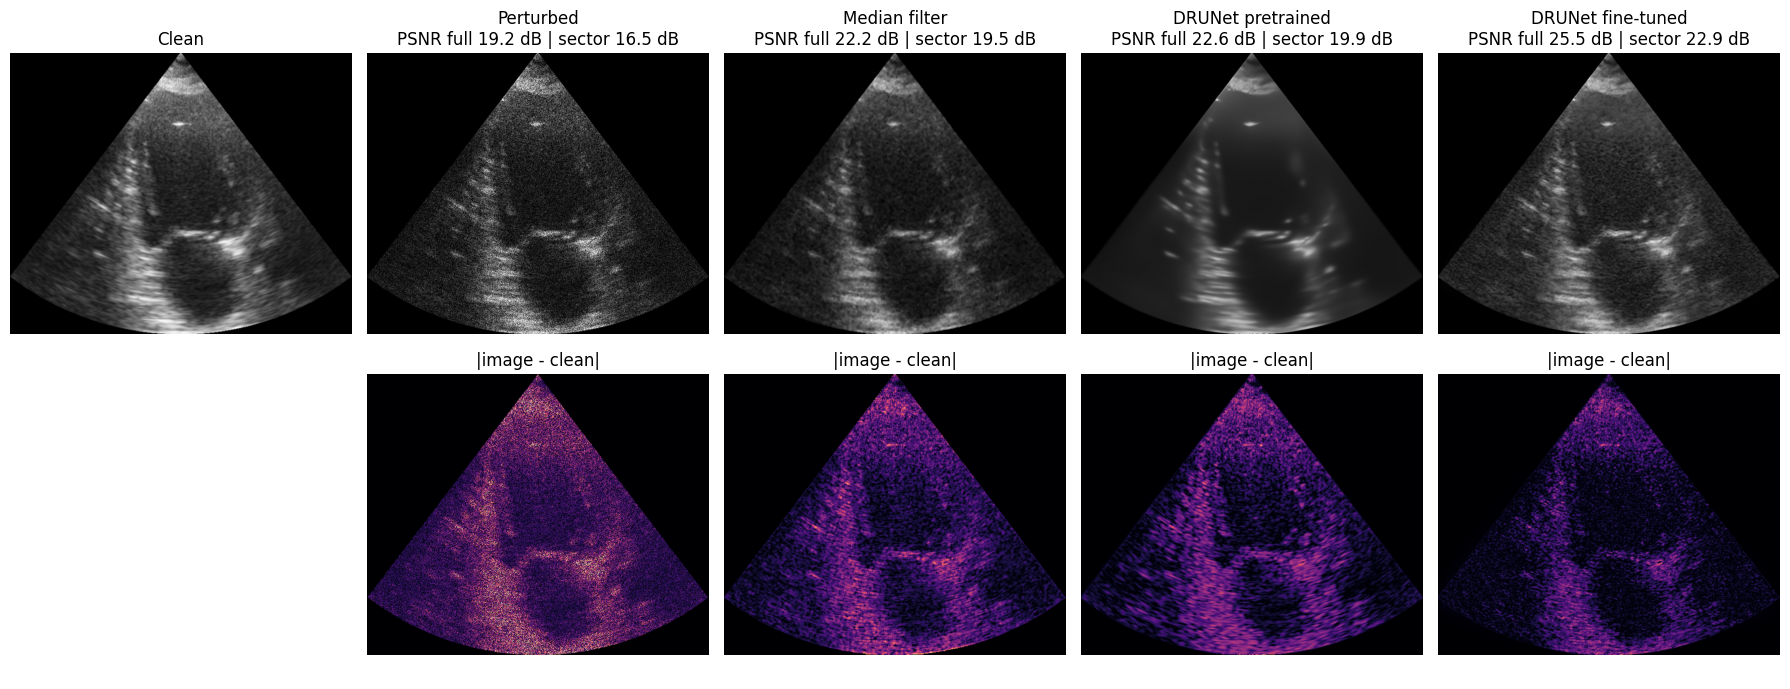

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes[0, 0].imshow(example_clean, cmap="gray", vmin=0, vmax=1); axes[0, 0].set_title("Clean")
axes[1, 0].axis("off")
for j, (name, img) in enumerate(example_versions.items(), start=1):
    psnr = peak_signal_noise_ratio(example_clean, img, data_range=1.0)
    psnr_sector, ssim_sector = masked_metrics(example_clean, img)
    axes[0, j].imshow(img, cmap="gray", vmin=0, vmax=1); axes[0, j].set_title(f"{name}\nPSNR full {psnr:.1f} dB | sector {psnr_sector:.1f} dB")
    axes[1, j].imshow(np.abs(img - example_clean), cmap="magma", vmin=0, vmax=0.5); axes[1, j].set_title("|image - clean|")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

The figure shows the reconstruction results for a single test image (the first image in the test set). The PSNR values displayed above each image refer only to this example, whereas the previous table reports the mean and standard deviation across all 200 test images.

The pretrained DRUNet produces a noticeably blurred reconstruction, removing not only some of the degradation but also image texture present in the clean reference. Fine-tuning improves the reconstruction and produces an image more similar to the original.

The difference maps in the second row highlight where each reconstructed image differs from the clean reference. Brighter regions correspond to larger absolute pixel differences.

### How to interpret the results

1. **Compare the pretrained and fine-tuned models.** Fine-tuning improves both PSNR and SSIM, suggesting that the pretrained network benefits from adapting to the CAMUS image domain and degradation characteristics.

2. **Compare deep learning with classical filtering.** The median filter provides a strong baseline. Although the fine-tuned DRUNet achieves higher SSIM, its sector PSNR is very similar to that of the median filter. A more complex model is not necessarily better according to every metric.

3. **Consider both the mean and the variability.** The standard deviations indicate that reconstruction quality varies across images. To assess whether one method consistently outperforms another, examine per-image differences rather than relying exclusively on average values.

4. **Inspect the reconstructed images.** Numerical metrics do not fully describe visual quality. Pay particular attention to the preservation of myocardial borders, ventricular structures and other relevant anatomical details. A visually smoother image is not necessarily more informative.

5. **Understand the limitations of the evaluation.** PSNR and SSIM measure similarity to the original CAMUS images, not diagnostic quality. Moreover, these experiments use synthetic degradations, which may not fully represent the characteristics of real echocardiographic data.

6. **Interpret the results within the experimental setup.** The selected noise level, training subset, fine-tuning strategy and synthetic perturbations influence the results. Additional experiments would be needed to evaluate generalization to different datasets and acquisition conditions.

### Does denoising performance depend on the type of noise?

The results presented above summarize denoising performance across the entire test set. However, different denoising methods may perform differently depending on the type and severity of image degradation.

For example, a median filter is particularly effective against impulse noise, whereas other degradation types may benefit from different filtering strategies or learned denoisers such as DRUNet.

An interesting extension would be to group the CAMUS test images according to their known synthetic degradation parameters and compare PSNR and SSIM separately for each group. This would help identify the conditions under which each denoising method performs best.

For in-house echocardiographic images, degradation characteristics are unknown and would need to be estimated. Since clean reference images are usually unavailable, full-reference metrics such as PSNR and SSIM cannot be computed directly. Alternative evaluation strategies, including visual assessment and downstream task performance, would therefore be necessary.

Importantly, ultrasound speckle can contain meaningful tissue information, so removing it does not necessarily improve image quality for subsequent clinical applications.

## From CAMUS to your project

The pretrained network needs no pairs, so it can be applied directly to your in-house images. Fine-tuning needs pairs of degraded and original images.

Remember: $\sigma$, learning rate and stopping epoch are chosen on your validation split, and the test split is touched once.

## Reference

* DeepInverse — [DRUNet API](https://deepinv.org/api/stubs/deepinv.models.DRUNet.html).